# Bölüm 1 — Veri Hazırlığı ve Keşif

Özellik kesim tarihi: 2025-06-30. Hedef penceresi: 2025-07-01 – 2026-06-30.

In [1]:
# --- Kurulum ---
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.2f}'.format)      # sayıları okunabilir biçimde göster

VERI = '../veri/'          # notebook kod/ klasöründe, veri bir üst klasörde
CIKTI = '../ciktilar/'
KESIM = pd.Timestamp('2025-06-30')      # özellik kesim tarihi
HEDEF_BIT = pd.Timestamp('2026-06-30')  # hedef penceresinin sonu

# --- Dört dosyayı yükle ---
musteriler = pd.read_csv(VERI + 'musteriler.csv')
araclar = pd.read_csv(VERI + 'araclar.csv')
servis = pd.read_csv(VERI + 'servis_kayitlari.csv')
yorumlar = pd.read_csv(VERI + 'geri_bildirimler.csv')

# --- Her tablo için: boyut, boş değerler, tamamen aynı satırlar ---
for ad, df in [('musteriler', musteriler), ('araclar', araclar),
               ('servis', servis), ('yorumlar', yorumlar)]:
    bos = df.isna().sum()
    print(f'=== {ad} {df.shape} ===')
    print('Boş değer olan sütunlar:', bos[bos > 0].to_dict())
    print('Tamamen aynı satır:', df.duplicated().sum())
    print()

=== musteriler (4235, 8) ===
Boş değer olan sütunlar: {'dogum_yili': 97, 'son_iletisim_notu': 1531}
Tamamen aynı satır: 35

=== araclar (4786, 8) ===
Boş değer olan sütunlar: {}
Tamamen aynı satır: 0

=== servis (32770, 8) ===
Boş değer olan sütunlar: {'memnuniyet_puani': 6875}
Tamamen aynı satır: 310

=== yorumlar (640, 5) ===
Boş değer olan sütunlar: {'metin': 11}
Tamamen aynı satır: 0



In [2]:
# Sonuç:
# - musteriler: 35 tamamen aynı satır (kopya) → aşağıda incelenecek.
#   dogum_yili 97 boş (sözlük: kurumsalda anlamsız olabilir, modelde kullanılmayacak).
#   son_iletisim_notu 1.531 boş (tarihsiz not; sızıntı kontrolünde ele alınacak).
# - servis: 310 tamamen aynı satır (kopya). memnuniyet_puani 6.875 boş (~%21; anket zorunlu değil).
# - araclar: temiz.
# - yorumlar: 11 boş metin (Bölüm 3'te ayıklanacak).

In [3]:
# Amaç: Değerlerin biçimi ve aralığı mantıklı mı?

# 1) Servis tarihleri nasıl yazılmış? (ilk 8 satır)
print(servis[['kayit_id', 'servis_tarihi', 'servis_tipi', 'tutar', 'memnuniyet_puani']].head(8).to_string())
print()

# 2) Sayısal sütunların aralığı
print(servis[['km', 'tutar', 'memnuniyet_puani']].describe())
print()

# 3) Şehir yazımları
print(musteriler['sehir'].value_counts().to_string())

   kayit_id        servis_tarihi      servis_tipi     tutar  memnuniyet_puani
0     21678  2023-04-26 00:00:00  Periyodik Bakım  5,319.69              5.00
1     12553           26/11/2023  Periyodik Bakım  9,200.00              4.00
2     29838           2025-03-24     Arıza Onarım 17,307.98              2.00
3     26597           2025-11-05    Lastik/Balans  3,686.55              4.00
4     28517           09.05.2025  Periyodik Bakım  5,716.90              4.00
5      3091           2025-07-12    Lastik/Balans  7,867.49               NaN
6       391           2024-04-19  Periyodik Bakım 11,526.30              4.00
7      8244           2025-08-23  Periyodik Bakım 10,929.65              5.00

             km        tutar  memnuniyet_puani
count 32,770.00    32,770.00         25,895.00
mean   1,264.10    12,999.48              3.94
std      709.74    37,063.98              0.83
min   -2,976.00   -47,222.59              1.00
25%      670.00     7,431.53              3.00
50%    1,188.00

In [4]:
# Sonuç:
# 1) servis_tarihi aynı sütunda farklı biçimlerde: 2023-04-26, 2023-04-26 00:00:00, 26/11/2023, 09.05.2025
#    → gün/ay sırası belirsiz, ayrıca incelenecek.
# 2) tutar: en küçük −47.222 TL (fatura negatif olamaz), en büyük ~2,9 milyon TL (gerçekçi değil).
#    Ortalama (13.000) ortancadan (9.900) belirgin yüksek → birkaç aşırı değer dağılımı bozuyor.
# 3) km: negatif değerler var (en küçük −2.976). Ayrıca sözlükteki ×1000 ölçeğiyle ortanca ~1,2 milyon km
#    ediyor, gerçekçi değil. km analizde kullanılmayacağı için yalnızca not ediliyor.
# 4) memnuniyet_puani 1–5 aralığında, sorun yok.
# 5) sehir: aynı şehir farklı yazımlarla (İstanbul / istanbul / ISTANBUL / Kocaelı ...).

## 1.2 Veri kalitesi — Sorun 1: Kopya kayıtlar

In [5]:
# Amaç: Kopyalar gerçekten "aynı kaydın iki kez yazılması" mı, yoksa çelişen bilgiler mi?
# Kimlik (id) tekrarı = tamamen aynı satır ise çelişki yok, silmek güvenli.
print('Müşteri — tekrar eden musteri_id:', musteriler['musteri_id'].duplicated().sum(),
      '| tamamen aynı satır:', musteriler.duplicated().sum())
print('Servis   — tekrar eden kayit_id:  ', servis['kayit_id'].duplicated().sum(),
      '| tamamen aynı satır:', servis.duplicated().sum())

# Amaç: Kopyalar birleştirmeyi nasıl etkiliyor?
# Her servis tek bir araca, her araç tek bir müşteriye ait → birleştirme satır sayısını değiştirmemeli.
ham = servis.merge(araclar, on='arac_id').merge(musteriler, on='musteri_id')
print(f'\nBirleştirme: {len(servis)} servis kaydı → {len(ham)} satır (fark: {len(ham) - len(servis)})')

Müşteri — tekrar eden musteri_id: 35 | tamamen aynı satır: 35
Servis   — tekrar eden kayit_id:   310 | tamamen aynı satır: 310

Birleştirme: 32770 servis kaydı → 33047 satır (fark: 277)


In [6]:
# Sonuç:
# - Müşteri: 35 tekrar, hepsi bütün sütunlarıyla birebir aynı → çelişen bilgi yok.
# - Servis: 310 tekrar, hepsi birebir aynı. kayit_id işlem numarası, iki farklı işlem aynı numarayı alamaz
#   → aynı işlem sisteme iki kez aktarılmış.
# - Birleştirme 277 fazla satır üretiyor: 35 kopya müşterinin bütün servis kayıtları ikiye katlanıyor.
#   Temizlenmezse bu müşterilerin ziyaret sayısı ve harcaması iki kat görünür.
# Karar: Birebir kopyalar silinecek (bilgi kaybı yok).

In [7]:
# Karar: İki tablodaki birebir kopyaları sil
musteriler = musteriler.drop_duplicates()
servis = servis.drop_duplicates()

# Kontrol: Birleştirme artık satır sayısını değiştirmemeli
birlesik = servis.merge(araclar, on='arac_id').merge(musteriler, on='musteri_id')
print('Müşteri:', len(musteriler), '| benzersiz id:', musteriler['musteri_id'].nunique())
print('Servis kaydı:', len(servis))
print('Birleştirme sonrası:', len(birlesik))

Müşteri: 4200 | benzersiz id: 4200
Servis kaydı: 32460
Birleştirme sonrası: 32460


In [8]:
# Sonuç: 4.200 benzersiz müşteri, 32.460 servis kaydı. Birleştirme sonrası satır = servis kaydı → şişme yok.

## 1.2 Veri kalitesi — Sorun 2: Tarih biçimleri

In [9]:
# Amaç: Kaç farklı tarih biçimi var? (rakamlar 9'a çevrilip gruplanıyor)
print(servis['servis_tarihi'].str.replace(r'\d', '9', regex=True).value_counts())
print()

# Amaç: '/' ve '.' biçimlerinde sıra gün/ay mı, ay/gün mü? (ay 12'yi geçemez)
# regex=False: contains() '.' karakterini 'herhangi bir karakter' sayar, düz metin araması gerekiyor
for ayrac in ['/', '.']:
    secilen = servis.loc[servis['servis_tarihi'].str.contains(ayrac, regex=False), 'servis_tarihi']
    parcalar = secilen.str.split(ayrac, expand=True).astype(int)
    print(f"'{ayrac}' biçimi ({len(secilen)} kayıt): ilk sayı >12: {(parcalar[0] > 12).sum()} | "
          f"ikinci sayı >12: {(parcalar[1] > 12).sum()}")

servis_tarihi
9999-99-99             22725
99/99/9999              3947
99.99.9999              3947
9999-99-99 99:99:99     1841
Name: count, dtype: int64

'/' biçimi (3947 kayıt): ilk sayı >12: 2379 | ikinci sayı >12: 0
'.' biçimi (3947 kayıt): ilk sayı >12: 2443 | ikinci sayı >12: 0


In [10]:
# Sonuç:
# - 4 biçim var. '/' ve '.' ile yazılan 7.894 kayıt (~%24) gün/ay karışıklığına açık.
# - İki biçimde de ilk sayı 12'yi geçebiliyor ama ikinci sayı hiç geçmiyor → sıra gün/ay/yıl.
# - Saatli biçimde saat hep 00:00:00, bilgi taşımıyor.

In [11]:
# Karar: Her biçimi açık kalıpla çevir (biçim vermeden çevirmek gün/ay'ı karıştırabilir)
def tarih_coz(x):
    if '/' in x: return pd.to_datetime(x, format='%d/%m/%Y')
    if '.' in x: return pd.to_datetime(x, format='%d.%m.%Y')
    if ' ' in x: return pd.to_datetime(x, format='%Y-%m-%d %H:%M:%S')
    return pd.to_datetime(x, format='%Y-%m-%d')

servis['tarih'] = servis['servis_tarihi'].apply(tarih_coz)

# Diğer tablolardaki tarihler tek biçimde
araclar['satin_alma_tarihi'] = pd.to_datetime(araclar['satin_alma_tarihi'], format='%Y-%m-%d')
araclar['garanti_bitis_tarihi'] = pd.to_datetime(araclar['garanti_bitis_tarihi'], format='%Y-%m-%d')
musteriler['ilk_temas_tarihi'] = pd.to_datetime(musteriler['ilk_temas_tarihi'], format='%Y-%m-%d')
yorumlar['tarih'] = pd.to_datetime(yorumlar['tarih'], format='%Y-%m-%d')

# Kontrol: boş tarih kalmamalı, aralık vakanın zaman çerçevesiyle uyumlu olmalı
print('Servis — boş tarih:', servis['tarih'].isna().sum(),
      '|', servis['tarih'].min().date(), '→', servis['tarih'].max().date())
print('Yorum  —', yorumlar['tarih'].min().date(), '→', yorumlar['tarih'].max().date())
print('Satın alma —', araclar['satin_alma_tarihi'].min().date(), '→', araclar['satin_alma_tarihi'].max().date())

Servis — boş tarih: 0 | 2022-01-21 → 2026-06-30
Yorum  — 2023-01-13 → 2025-06-30
Satın alma — 2013-01-01 → 2025-12-27


In [12]:
# Sonuç:
# - Servis: boş tarih yok, aralık vakanın zaman çerçevesiyle uyumlu → çeviri doğru.
# - Yorumların hepsi kesim tarihinden (2025-06-30) önce → özellik olarak kullanılabilir.
# - Bazı araçlar kesimden sonra satın alınmış (en yenisi 2025-12) → araç özelliklerinde dışarıda bırakılacak.

## 1.2 Veri kalitesi — Sorun 3: Tutar anomalileri

In [13]:
# Amaç: Normal ile hatalı değerler arasındaki sınırı veriden bulmak
# Gerçek pahalı işlemler olsaydı değerler kademeli artardı; hatalı kayıtlar olsaydı arada bir boşluk olurdu
print('En büyük 50 tutar:')
print(servis['tutar'].nlargest(50).round(0).astype(int).tolist())
print()
print('Negatif tutar:', (servis['tutar'] < 0).sum())
print('Sıfır tutar:', (servis['tutar'] == 0).sum())

En büyük 50 tutar:
[2886854, 2350557, 2104598, 1828645, 1467504, 1176961, 1164323, 1144048, 1108038, 1008006, 982225, 947395, 906204, 900852, 835199, 834400, 816791, 811808, 763989, 763152, 729674, 719825, 689441, 669406, 665698, 627864, 591047, 589721, 575356, 543437, 537236, 536506, 495129, 464476, 439470, 438860, 384402, 361866, 349527, 341375, 320546, 290624, 260417, 97343, 88709, 72212, 64058, 62950, 62735, 62087]

Negatif tutar: 150
Sıfır tutar: 220


In [14]:
# Sonuç:
# - 260.417'den 97.343'e ani düşüş: üstte 43 değer, arada hiç değer yok → sınır 100.000 TL.
#   Gerçek pahalı işlemler olsaydı 100–260 bin arası da dolu olurdu → üstteki 43 değer büyük ihtimalle hatalı giriş.
# - 150 negatif, 220 sıfır tutar.
# Üç grup için ayrı hipotezler test edilecek.

In [15]:
normal = servis[(servis['tutar'] > 0) & (servis['tutar'] < 100_000)]
buyuk = servis[servis['tutar'] >= 100_000]
negatif = servis[servis['tutar'] < 0]
pozitif = servis[servis['tutar'] > 0]

# Hipotez 1: Büyük tutarlar kuruş mu? (öyleyse kat sabit ~100 olmalı)
# Servis tipine göre karşılaştırıyoruz, çünkü lastik ile kaporta işinin fiyatı çok farklı
kat = buyuk.groupby('servis_tipi')['tutar'].median() / normal.groupby('servis_tipi')['tutar'].median()
print('1) Büyük / normal ortanca katı (servis tipine göre):', kat.round(0).to_dict())

# Hipotez 2: Negatifler iade mi? (öyleyse aynı araçta ±30 gün içinde pozitif fatura olmalı)
yakin = negatif[['arac_id', 'tarih']].merge(pozitif[['arac_id', 'tarih']], on='arac_id', suffixes=('', '_p'))
print('2) ±30 gün içinde eşleşen pozitif fatura:', ((yakin['tarih_p'] - yakin['tarih']).dt.days.abs() <= 30).sum())
print('   Negatiflerin mutlak değer ortancası:', negatif['tutar'].abs().median().round(0),
      '| normal ortanca:', normal['tutar'].median().round(0))

# Hipotez 3: Sıfırlar garanti kapsamında mı? (öyleyse sıfırlarda garanti oranı belirgin yüksek olmalı)
gs = servis.merge(araclar[['arac_id', 'garanti_bitis_tarihi']], on='arac_id')
garantide = gs['tarih'] <= gs['garanti_bitis_tarihi']
print(f"3) Garanti dönemindeki oran: sıfırlarda {garantide[gs['tutar'] == 0].mean():.2f}, tümünde {garantide.mean():.2f}")

1) Büyük / normal ortanca katı (servis tipine göre): {'Arıza Onarım': 65.0, 'Kaporta/Boya': 58.0, 'Lastik/Balans': 85.0, 'Periyodik Bakım': 62.0}
2) ±30 gün içinde eşleşen pozitif fatura: 0
   Negatiflerin mutlak değer ortancası: 10328.0 | normal ortanca: 9953.0
3) Garanti dönemindeki oran: sıfırlarda 0.29, tümünde 0.28


In [16]:
# Sonuç:
# 1) Kat 58–85 arası, sabit 100 değil → kuruş hipotezi tutmuyor, doğru değer geri hesaplanamıyor.
# 2) ±30 günde eşleşen pozitif fatura yok → iade değil. Mutlak değerleri normal tutarlarla aynı seviyede → işaret hatası.
# 3) Garanti oranı sıfırlarda %29, genelde %28 → sıfırlar garantiyle açıklanmıyor; eksik giriş varsayımı.

In [17]:
# Kontrol 1: Anormal kayıtları aynı aracın aynı tipteki normal faturalarıyla karşılaştır
# (bütün araçların ortancası yerine aracın kendi ortancası → araç/model farkı ortadan kalkar)
arac_ortanca = normal.groupby(['arac_id', 'servis_tipi'])['tutar'].median().rename('arac_ortanca')
neg = negatif.join(arac_ortanca, on=['arac_id', 'servis_tipi'])
byk = buyuk.join(arac_ortanca, on=['arac_id', 'servis_tipi'])
print('Negatif / aracın kendi ortancası — ortanca:', (neg['tutar'].abs() / neg['arac_ortanca']).median().round(2))
oran = byk['tutar'] / byk['arac_ortanca']
print('Büyük / aracın kendi ortancası — en küçük:', oran.min().round(0), '| en büyük:', oran.max().round(0))

# Kontrol 2: Sıfırlar belirli bir servis tipinde (ör. garantili arıza onarımı) yoğunlaşıyor mu?
gs['sifir'] = gs['tutar'] == 0
print()
print(pd.crosstab([gs['servis_tipi'], garantide], gs['sifir'], normalize='index').mul(100).round(2))

# Kontrol 3: Anomaliler belirli bir kaynak sisteme mi bağlı? (sözlük: farklı tarih biçimleri = farklı kaynak sistemler)
bicim = servis['servis_tarihi'].str.replace(r'\d', '9', regex=True)
anomali = np.select([servis['tutar'] < 0, servis['tutar'] == 0, servis['tutar'] >= 100_000],
                    ['negatif', 'sıfır', 'büyük'], 'normal')
print()
print(pd.crosstab(bicim, anomali, normalize='index').mul(100).round(2))

Negatif / aracın kendi ortancası — ortanca: 1.03
Büyük / aracın kendi ortancası — en küçük: 33.0 | en büyük: 278.0

sifir                  False  True 
servis_tipi     row_1              
Arıza Onarım    False  99.35   0.65
                True   99.09   0.91
Kaporta/Boya    False  99.33   0.67
                True   99.20   0.80
Lastik/Balans   False  99.19   0.81
                True   99.58   0.42
Periyodik Bakım False  99.35   0.65
                True   99.34   0.66

col_0                büyük  negatif  normal  sıfır
servis_tarihi                                     
99.99.9999            0.10     0.41   98.76   0.73
99/99/9999            0.18     0.43   98.76   0.63
9999-99-99            0.12     0.48   98.72   0.68
9999-99-99 99:99:99   0.22     0.38   98.75   0.65


In [18]:
# Sonuç:
# 1) Negatifler, eksi atılınca aracın kendi normal faturasının ~1,03 katı → işaret hatası güçlü şekilde destekleniyor.
#    Büyükler aracın kendi normalinin 33–278 katı, sabit çarpan yok → hatalı giriş, doğru değer geri hesaplanamıyor.
# 2) Sıfır oranı her servis tipinde ~%0,7. Garantideki onarımların %99'u sıfırdan farklı faturalanmış
#    → sistem garantili işi sıfır TL olarak kaydetmiyor, garanti hipotezi desteklenmiyor.
# 3) Anomali oranları dört tarih biçiminde (kaynak sistemde) benzer → belirli bir sisteme bağlı değil, dağınık giriş hataları.

In [19]:
# Karar (tutar):
#   ≥100 bin → boş: hatalı giriş, doğru değer geri hesaplanamıyor
#   negatif  → mutlak değer: iade değil, büyüklüğü normal → işaret hatası
#   sıfır    → boş: garantiyle açıklanmıyor → eksik giriş varsayımı ('bilinmiyor' ≠ 'sıfır')
# Orijinal 'tutar' korunuyor; kayıtlar silinmiyor, ziyaret olarak sayılmaya devam ediyor
servis['tutar_temiz'] = servis['tutar']
servis.loc[servis['tutar'] >= 100_000, 'tutar_temiz'] = np.nan
servis.loc[servis['tutar'] < 0, 'tutar_temiz'] = servis['tutar'].abs()
servis.loc[servis['tutar'] == 0, 'tutar_temiz'] = np.nan

# Karar (km): negatifler aynı türden işaret hatası → mutlak değer
print('Negatif km:', (servis['km'] < 0).sum(),
      '| negatiflerin mutlak ortancası:', servis.loc[servis['km'] < 0, 'km'].abs().median(),
      '| pozitif ortanca:', servis.loc[servis['km'] > 0, 'km'].median())
servis['km_temiz'] = servis['km'].abs()

# Kontrol
print('Boş tutar:', servis['tutar_temiz'].isna().sum())
print(servis[['tutar', 'tutar_temiz']].describe().round(0))

Negatif km: 40 | negatiflerin mutlak ortancası: 1221.5 | pozitif ortanca: 1190.0
Boş tutar: 263
             tutar  tutar_temiz
count    32,460.00    32,197.00
mean     13,013.00    12,104.00
std      37,232.00     7,852.00
min     -47,223.00       400.00
25%       7,433.00     7,522.00
50%       9,909.00     9,953.00
75%      13,168.00    13,211.00
max   2,886,854.00    97,343.00


In [20]:
# Sonuç:
# - km: 40 negatif, mutlak değerleri pozitiflerle aynı seviyede (1.222 / 1.190) → işaret hatası, mutlak değer alındı.
# - tutar: 263 kayıt boş (43 büyük + 220 sıfır). En küçük 400, en büyük 97.343 TL.
#   Standart sapma 37.232 → 7.852 (beşte bire indi), ortanca neredeyse değişmedi (9.909 → 9.953)
#   → dağılımı bozan şey birkaç düzine hatalı kayıtmış.

## Diğer düzeltmeler

In [21]:
# Amaç: Aynı şehrin farklı yazımlarını birleştirmek
print('Önce:', musteriler['sehir'].nunique(), 'farklı yazım')

# Neden basit lower() kullanılmıyor? Türkçe 'İ' küçültülünce görünmez bir nokta karakteri ekleniyor
print("'İstanbul'.lower() uzunluğu:", len('İstanbul'.lower()), "| 'istanbul' uzunluğu:", len('istanbul'))

# Karar: Türkçe harfleri düzleştirip açık bir sözlükle eşle (sözlükte olmayan bir değer gelirse hata verir)
def sehir_duzelt(x):
    x = x.strip().replace('İ', 'I').replace('ı', 'i').upper()
    return {'ISTANBUL': 'İstanbul', 'ANKARA': 'Ankara', 'IZMIR': 'İzmir', 'BURSA': 'Bursa',
            'ANTALYA': 'Antalya', 'KOCAELI': 'Kocaeli', 'ADANA': 'Adana'}[x]

musteriler['sehir'] = musteriler['sehir'].apply(sehir_duzelt)
print('Sonra:', musteriler['sehir'].value_counts().to_dict())

Önce: 21 farklı yazım
'İstanbul'.lower() uzunluğu: 9 | 'istanbul' uzunluğu: 8
Sonra: {'İstanbul': 1778, 'Ankara': 709, 'İzmir': 555, 'Bursa': 333, 'Antalya': 326, 'Kocaeli': 281, 'Adana': 218}


In [22]:
# Sonuç: 21 yazım → 7 şehir, toplam 4.200. Basit lower() Türkçe 'İ'de görünmez karakter ekliyor (9 karakter)
# → açık eşleme sözlüğü gerekli.

In [23]:
# Amaç: Tablolar arası tutarlılık ve mantık kontrolleri

# 1) Referans bütünlüğü: her kaydın bağlı olduğu kayıt var mı?
print('Aracı olmayan servis:', (~servis['arac_id'].isin(araclar['arac_id'])).sum(),
      '| Müşterisi olmayan araç:', (~araclar['musteri_id'].isin(musteriler['musteri_id'])).sum(),
      '| Aracı olmayan yorum:', (~yorumlar['arac_id'].isin(araclar['arac_id'])).sum())

# 2) Gizli kopya: aynı araç, aynı gün birden fazla servis (farklı kayit_id ile)?
print('Aynı araç + aynı gün:', servis.duplicated(subset=['arac_id', 'tarih']).sum())

# 3) Tarih mantığı: satın almadan önce servis ya da yorum olabilir mi?
sa = servis.merge(araclar[['arac_id', 'satin_alma_tarihi']], on='arac_id')
ya = yorumlar.merge(araclar[['arac_id', 'satin_alma_tarihi']], on='arac_id')
print('Satın almadan önce servis:', (sa['tarih'] < sa['satin_alma_tarihi']).sum(),
      '| Satın almadan önce yorum:', (ya['tarih'] < ya['satin_alma_tarihi']).sum())

# 4) Doğum yılı: imkânsız değerler ve kurumsal müşteriler
dy = musteriler['dogum_yili']
print('Doğum yılı <1930:', (dy < 1930).sum(), '| >2007 (18 yaş altı):', (dy > 2007).sum(),
      '| Kurumsalda dolu:', musteriler.loc[musteriler['musteri_tipi'] == 'Kurumsal', 'dogum_yili'].notna().sum())

# 5) Memnuniyet boşlukları rastgele mi? (servis tipine ve merkeze göre cevapsız oran)
cevapsiz = servis['memnuniyet_puani'].isna()
print('\nCevapsız oran — servis tipine göre:', cevapsiz.groupby(servis['servis_tipi']).mean().round(3).to_dict())
print('Cevapsız oran — merkeze göre:', cevapsiz.groupby(servis['servis_merkezi']).mean().round(3).to_dict())

Aracı olmayan servis: 0 | Müşterisi olmayan araç: 0 | Aracı olmayan yorum: 0
Aynı araç + aynı gün: 0
Satın almadan önce servis: 0 | Satın almadan önce yorum: 74
Doğum yılı <1930: 9 | >2007 (18 yaş altı): 9 | Kurumsalda dolu: 717

Cevapsız oran — servis tipine göre: {'Arıza Onarım': 0.264, 'Kaporta/Boya': 0.219, 'Lastik/Balans': 0.202, 'Periyodik Bakım': 0.192}
Cevapsız oran — merkeze göre: {'SM-Ankara1': 0.209, 'SM-Antalya1': 0.199, 'SM-Bursa1': 0.213, 'SM-Kadıköy': 0.211, 'SM-Kocaeli1': 0.206, 'SM-Maslak': 0.213, 'SM-İzmir1': 0.208}


In [24]:
# Sonuç:
# - Referans bütünlüğü tam, gizli kopya yok, satın almadan önce servis yok → tablolar tutarlı.
# - 74 yorum (%12) aracın satın alma tarihinden önce yazılmış → araç ikinci el alınmış, yorum önceki sahibe ait olabilir.
#   Karar: yorumlar müşteriye bağlanırken yalnızca satın alma sonrası yorumlar kullanılacak.
# - Doğum yılı: 18 imkânsız değer, kurumsal müşterilerin 717'sinde dolu → modelde kullanılmıyor.
# - Memnuniyet cevapsızlığı arıza onarımında daha yüksek (%26 / periyodik bakım %19) → boşluklar rastgele değil,
#   sorun yaşayan daha az cevaplıyor. Ortalama ile doldurmak yanıltıcı olur; ortalamalar biraz iyimser olabilir.
#   Merkezler arasında oran eşit (%20–21) → merkez karşılaştırması (1.4) adil.

## 1.1 Analiz tablosu (müşteri seviyesi)

Her tablo önce müşteri seviyesine özetlenir, sonra `musteri_id` ile birleştirilir. Servis ve geri bildirim tabloları araca N'e N bağlı olduğundan satır seviyesinde birleştirmek satırları şişirir.

In [25]:
# Amaç: Kesim tarihine göre geçmiş (özellikler için) ve gelecek (yalnızca hedef için) ayrımı
sa = servis.merge(araclar[['arac_id', 'musteri_id']], on='arac_id')
gecmis = sa[sa['tarih'] <= KESIM]
gelecek = sa[(sa['tarih'] > KESIM) & (sa['tarih'] <= HEDEF_BIT)]
print('Geçmiş:', len(gecmis), '| Gelecek:', len(gelecek), '| Toplam:', len(gecmis) + len(gelecek), '/', len(sa))

# RFM: yalnızca geçmiş kayıtlardan; recency bugüne değil kesim tarihine göre
rfm = gecmis.groupby('musteri_id').agg(
    son_servis=('tarih', 'max'),
    frequency=('kayit_id', 'count'),
)
rfm['recency_gun'] = (KESIM - rfm['son_servis']).dt.days
# min_count=1: tutarları tamamen boş müşterinin toplamı 0 değil boş kalsın ('bilinmiyor' ≠ 'sıfır')
rfm['monetary'] = gecmis.groupby('musteri_id')['tutar_temiz'].sum(min_count=1)

# Hedef: hedef penceresinde hiç servis kaydı yoksa churn = 1
rfm['churn'] = (~rfm.index.isin(gelecek['musteri_id'])).astype(int)

print('\nPopülasyon (kesimden önce en az 1 servis):', len(rfm), '/', musteriler['musteri_id'].nunique())
print('Terk:', rfm['churn'].sum(), f"(%{rfm['churn'].mean() * 100:.1f})")
print('En küçük recency:', rfm['recency_gun'].min(), '| Boş monetary:', rfm['monetary'].isna().sum())
print(rfm[['recency_gun', 'frequency', 'monetary']].describe().round(0))

Geçmiş: 25061 | Gelecek: 7399 | Toplam: 32460 / 32460

Popülasyon (kesimden önce en az 1 servis): 3974 / 4200
Terk: 658 (%16.6)
En küçük recency: 0 | Boş monetary: 2
       recency_gun  frequency   monetary
count     3,974.00   3,974.00   3,972.00
mean        117.00       6.00  75,668.00
std          85.00       3.00  42,697.00
min           0.00       1.00     400.00
25%          49.00       5.00  47,304.00
50%         102.00       6.00  67,707.00
75%         168.00       7.00  96,086.00
max         413.00      24.00 330,357.00


In [26]:
# Sonuç:
# - 25.061 geçmiş + 7.399 gelecek = 32.460 → dışarıda kalan kayıt yok.
# - Popülasyon 3.974 müşteri: 226 müşterinin kesimden önce servisi yok (ya hiç yok ya da ilki kesimden sonra).
# - 658 terk (%16,6) → sınıflar dengesiz; herkese "terk etmez" diyen model bile %83,4 doğruluk alır.
# - Ortancalar: recency 102 gün, frequency 6 ziyaret, monetary ~67.700 TL.
# - Recency en fazla 413 gün: popülasyondaki herkes kesimden önceki ~13 ayda en az bir kez gelmiş.
# - 2 müşterinin bütün tutarları boş → monetary "bilinmiyor" olarak boş bırakıldı (0 değil).

In [27]:
# Servis geçmişinden ek özellikler (yalnızca geçmiş kayıtlar)
ek = gecmis.sort_values('tarih').groupby('musteri_id').agg(
    ort_memnuniyet=('memnuniyet_puani', 'mean'),                        # boşlar atlanıyor
    anket_cevap_orani=('memnuniyet_puani', lambda x: x.notna().mean()),  # boşluğun kendisi de bilgi
    ariza_orani=('servis_tipi', lambda x: (x == 'Arıza Onarım').mean()),
    son_km=('km_temiz', 'last'),                                         # kesim öncesi son servisteki km
)
rfm = rfm.join(ek)

# Araç özellikleri: yalnızca kesimde sahip olunan araçlar (sonradan alınanlar gelecek bilgisi)
print('Kesimden sonra alınan araç:', (araclar['satin_alma_tarihi'] > KESIM).sum())
araclar_k = araclar[araclar['satin_alma_tarihi'] <= KESIM]
rfm = rfm.join(araclar_k.groupby('musteri_id').agg(
    arac_sayisi=('arac_id', 'count'),
    en_yeni_model_yili=('model_yili', 'max'),
    garantide_arac=('garanti_bitis_tarihi', lambda x: (x > KESIM).sum()),
))

print('Boş değerler:', rfm.isna().sum()[rfm.isna().sum() > 0].to_dict())
print(rfm[['ort_memnuniyet', 'anket_cevap_orani', 'ariza_orani', 'son_km', 'arac_sayisi']].describe().round(2))

Kesimden sonra alınan araç: 180
Boş değerler: {'monetary': 2, 'ort_memnuniyet': 47}
       ort_memnuniyet  anket_cevap_orani  ariza_orani   son_km  arac_sayisi
count        3,927.00           3,974.00     3,974.00 3,974.00     3,974.00
mean             3.97               0.79         0.21 1,633.54         1.14
std              0.46               0.19         0.19   561.99         0.35
min              1.50               0.00         0.00    28.00         1.00
25%              3.67               0.67         0.00 1,364.25         1.00
50%              4.00               0.80         0.20 1,726.50         1.00
75%              4.25               1.00         0.33 2,006.00         1.00
max              5.00               1.00         1.00 3,230.00         2.00


In [28]:
# Sonuç:
# - 180 araç kesimden sonra alınmış, araç özelliklerine katılmadı (gelecek bilgisi).
# - 47 müşteri hiç ankete cevap vermemiş (ort_memnuniyet boş, anket_cevap_orani 0).
# - Müşterilerin çoğunun tek aracı var (en fazla 2).
# - son_km'de boşluk yok; değerler pozitif (negatifler düzeltildi).

In [29]:
# Müşteri bilgileri. crm_musteri_durumu ve son_iletisim_notu bilerek alınmıyor (aşağıda sızıntı kontrolü)
rfm = rfm.join(musteriler.set_index('musteri_id')[['sehir', 'musteri_tipi', 'kayit_kanali', 'ilk_temas_tarihi']])

# Dördüncü dosya: kesim öncesi geri bildirim sayısı
# Yalnızca satın alma sonrası yorumlar (öncekiler büyük ihtimalle aracın önceki sahibine ait)
ya = yorumlar.merge(araclar[['arac_id', 'musteri_id', 'satin_alma_tarihi']], on='arac_id')
ya = ya[(ya['tarih'] <= KESIM) & (ya['tarih'] >= ya['satin_alma_tarihi'])]
rfm = rfm.join(ya.groupby('musteri_id').size().rename('geri_bildirim_sayisi'))
rfm['geri_bildirim_sayisi'] = rfm['geri_bildirim_sayisi'].fillna(0).astype(int)   # burada boş = gerçekten 0 yorum

print('Tablo:', rfm.shape)
print('Geri bildirimi olan müşteri oranı:', (rfm['geri_bildirim_sayisi'] > 0).mean().round(3))
print('Terk oranı — geri bildirimi yok / var:',
      rfm.groupby(rfm['geri_bildirim_sayisi'] > 0)['churn'].mean().round(3).to_dict())

# Sızıntı kontrolü: Bu iki alan 2025-06-30'da biliniyor muydu?
# Sözlük: crm_musteri_durumu "bugün itibarıyla" durum, son_iletisim_notu tarihsiz not
kontrol = rfm[['churn']].join(musteriler.set_index('musteri_id')[['crm_musteri_durumu', 'son_iletisim_notu']])
print()
print(pd.crosstab(kontrol['crm_musteri_durumu'], kontrol['churn'], normalize='index').round(2))
print()
print(pd.crosstab(kontrol['son_iletisim_notu'].fillna('(boş)'), kontrol['churn'], normalize='index').round(2))

# İş açısından: terk edenler neden gitmiş? (model için değil, açıklama için)
print('\nTerk edenlerin son notu:')
print(kontrol.loc[kontrol['churn'] == 1, 'son_iletisim_notu'].fillna('(not yok)').value_counts().to_string())

# Kaydet (Bölüm 2 bu dosyayı okur)
rfm.to_csv(CIKTI + 'analiz_tablosu.csv')
print('\nKaydedildi:', rfm.shape)

Tablo: (3974, 17)
Geri bildirimi olan müşteri oranı: 0.13
Terk oranı — geri bildirimi yok / var: {False: 0.167, True: 0.154}

churn                 0    1
crm_musteri_durumu          
Aktif              0.99 0.01
Kaybedildi         0.00 1.00
Pasif              0.56 0.44

churn                           0    1
son_iletisim_notu                     
(boş)                        0.92 0.08
Araç satıldı                 0.00 1.00
Başka servise geçti          0.00 1.00
Kampanya bilgilendirmesi     1.00 0.00
Memnuniyet araması           1.00 0.00
Randevu hatırlatması yapıldı 1.00 0.00
Ulaşılamadı                  0.00 1.00
İlgilenmiyor                 0.00 1.00

Terk edenlerin son notu:
son_iletisim_notu
Araç satıldı           146
Başka servise geçti    144
İlgilenmiyor           128
Ulaşılamadı            123
(not yok)              117

Kaydedildi: (3974, 17)


In [30]:
# Sonuç:
# - Analiz tablosu: 3.974 müşteri, 17 sütun. Dört dosyanın bilgisi müşteri başına tek satırda.
# - Geri bildirim: müşterilerin %13'ünün kesim öncesi yorumu var; terk oranları yakın (%16,7 / %15,4) → zayıf sinyal.
# - Sızıntı: "Kaybedildi" ve dört not türü %100 terk → bu alanlar terk gerçekleştikten sonra yazılmış, modele girmez.
# - Terk nedenleri (yalnızca açıklama için): 658 terk edenin 146'sı (%22) aracını satmış → önlenebilir bir kayıp değil.
#   Rakibe geçtiği açıkça bilinen 144 (%22). Hedef tanımı önlenemeyen terki de içeriyor (model sınırı olarak raporlanacak).

## 1.3 Keşifsel analiz

In [31]:
# Yardımcı değişkenler (yalnızca analiz için)
rfm['arac_yasi'] = 2025 - rfm['en_yeni_model_yili']
rfm['garantide_var'] = (rfm['garantide_arac'] > 0).astype(int)

# Amaç: Sayısal değişkenlerde terk eden ve kalan müşterilerin "tipik" değerleri (ortanca: uç değerlerden etkilenmez)
sayisal = ['recency_gun', 'frequency', 'monetary', 'ort_memnuniyet', 'anket_cevap_orani',
           'ariza_orani', 'son_km', 'arac_yasi', 'arac_sayisi', 'geri_bildirim_sayisi']
k = rfm.groupby('churn')[sayisal].median().T
k.columns = ['kalan (0)', 'terk eden (1)']
print(k.round(2))

# Amaç: Kategorik gruplarda terk oranı (genel oran %16,6)
for sutun in ['musteri_tipi', 'garantide_var', 'kayit_kanali', 'sehir']:
    print()
    print(rfm.groupby(sutun)['churn'].agg(terk_orani='mean', musteri_sayisi='size').round(3))

                      kalan (0)  terk eden (1)
recency_gun               93.00         174.00
frequency                  6.00           5.00
monetary              69,014.99      60,611.24
ort_memnuniyet             4.00           3.78
anket_cevap_orani          0.82           0.80
ariza_orani                0.20           0.20
son_km                 1,754.00       1,625.00
arac_yasi                  6.00           8.00
arac_sayisi                1.00           1.00
geri_bildirim_sayisi       0.00           0.00

              terk_orani  musteri_sayisi
musteri_tipi                            
Bireysel            0.18            3270
Kurumsal            0.09             704

               terk_orani  musteri_sayisi
garantide_var                            
0                    0.19            2956
1                    0.10            1018

                terk_orani  musteri_sayisi
kayit_kanali                              
Bayi                  0.15            2230
Mobil Uygulama     

In [32]:
# Sonuç:
# - Belirgin ayrışanlar: recency (93 → 174 gün), araç yaşı (6 → 8), memnuniyet (4,00 → 3,78),
#   son km (1.754 → 1.625), frequency ve monetary (biraz).
# - Ayrışmayanlar: arıza oranı, anket cevap oranı, araç sayısı → "çok arızayla gelen bıkıp gidiyor" hipotezi desteklenmedi.
# - Kategorik: kurumsal %9 / bireysel %18; garantili %10 / garantisiz %19.
#   Kanal (%15–19) ve şehir (%15–20) farkları küçük; Bursa %20 ama 312 kişi, tesadüf olabilir.

### Bulgu 1: Son servisten bu yana geçen süre

              terk_orani  musteri_sayisi
recency_grup                            
0-60                0.09            1227
61-120              0.11            1086
121-150             0.14             446
151-180             0.14             366
181-210             0.18             253
211-240             0.26             221
241-300             0.42             235
300+                0.80             140

180+ gün: müşterilerin %21'i, terk edenlerin %48'i


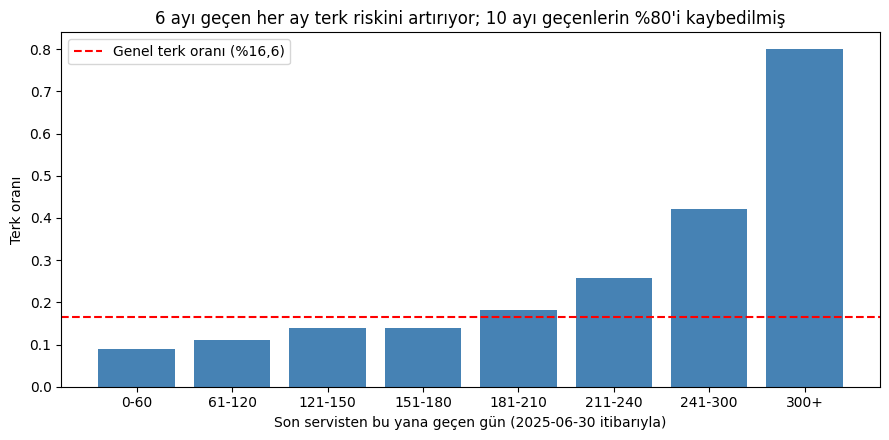

In [33]:
# Amaç: Recency arttıkça terk oranı nasıl değişiyor? Bir eşik var mı?
# 180 gün civarında dar aralıklar: eşiği yakalamak için
sinirlar = [0, 60, 120, 150, 180, 210, 240, 300, 420]
etiketler = ['0-60', '61-120', '121-150', '151-180', '181-210', '211-240', '241-300', '300+']
rfm['recency_grup'] = pd.cut(rfm['recency_gun'], bins=sinirlar, labels=etiketler, include_lowest=True)

ozet = rfm.groupby('recency_grup', observed=True)['churn'].agg(terk_orani='mean', musteri_sayisi='size')
print(ozet.round(3))

# 6 ayı geçenler ne kadar önemli?
uzun = rfm['recency_gun'] > 180
print(f"\n180+ gün: müşterilerin %{uzun.mean() * 100:.0f}'i, terk edenlerin %{rfm.loc[uzun, 'churn'].sum() / rfm['churn'].sum() * 100:.0f}'i")

# Grafik
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(ozet.index.astype(str), ozet['terk_orani'], color='steelblue')
ax.axhline(rfm['churn'].mean(), color='red', linestyle='--', label='Genel terk oranı (%16,6)')
ax.set_ylabel('Terk oranı')
ax.set_xlabel('Son servisten bu yana geçen gün (2025-06-30 itibarıyla)')
ax.set_title("6 ayı geçen her ay terk riskini artırıyor; 10 ayı geçenlerin %80'i kaybedilmiş")
ax.legend()
plt.tight_layout()
plt.savefig(CIKTI + 'bulgu1_recency.png', dpi=150, bbox_inches='tight')
plt.show()

In [34]:
# Sonuç:
# - 6 aya kadar terk oranı düşük ve sabit (%9–14), sonra her ay artıyor: 7. ay %18, 8. ay %26, 9–10. ay %42, 10+ ay %80.
# - En küçük grup bile 140 müşteri → oranlar güvenilir.
# - 180+ gün: müşterilerin %21'i ama terk edenlerin %48'i → "6 aydır gelmeyeni ara" kuralı terk edenlerin yarısına ulaşır.
# - Ama diğer yarı son 6 ayda gelmiş → recency tek başına yetmiyor, model gerekiyor.

### Bulgu 2: Araç yaşı ve kullanım yoğunluğu;

Yaşa göre terk oranı:
           terk_orani  musteri_sayisi
yas_grubu                            
0-4              0.11            1526
5-8              0.17            1299
9+               0.24            1149

Ortanca model yılı — garanti yok / var: {0: 2018.0, 1: 2023.0}

Aynı yaş grubunda terk oranı (sütun: garanti var mı):
garantide_var    0    1
yas_grubu              
0-4           0.12 0.10
5-8           0.17 0.26
9+            0.24  NaN
garantide_var     0    1
yas_grubu               
0-4             543  983
5-8            1264   35
9+             1149    0

Aynı yaş grubunda terk oranı (sütun: km grubu):
km_grubu   düşük km  orta km  yüksek km
yas_grubu                              
0-4            0.13     0.09       0.02
5-8            0.32     0.19       0.10
9+             0.41     0.26       0.17


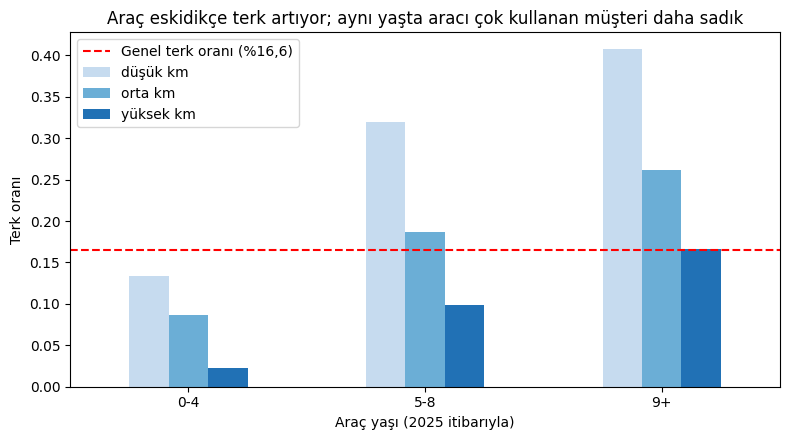

In [35]:
# 1) Araç yaşı arttıkça terk oranı nasıl değişiyor?
rfm['yas_grubu'] = pd.cut(rfm['arac_yasi'], bins=[-1, 4, 8, 20], labels=['0-4', '5-8', '9+'])
print('Yaşa göre terk oranı:')
print(rfm.groupby('yas_grubu', observed=True)['churn'].agg(terk_orani='mean', musteri_sayisi='size').round(3))

# 2) Garanti ile yaş iç içe mi? Garantili araçlar yeni araçlar mı?
print('\nOrtanca model yılı — garanti yok / var:',
      rfm.groupby('garantide_var')['en_yeni_model_yili'].median().to_dict())

# 3) Yaş sabitken garanti fark yaratıyor mu? (aynı yaş grubunda garantili / garantisiz)
print('\nAynı yaş grubunda terk oranı (sütun: garanti var mı):')
print(pd.crosstab(rfm['yas_grubu'], rfm['garantide_var'], values=rfm['churn'], aggfunc='mean').round(3))
print(pd.crosstab(rfm['yas_grubu'], rfm['garantide_var']))   # hücre büyüklükleri

# 4) Yaş sabitken km fark yaratıyor mu? (km'yi üç eşit gruba bölüyoruz)
rfm['km_grubu'] = pd.qcut(rfm['son_km'], 3, labels=['düşük km', 'orta km', 'yüksek km'])
km_tablo = pd.crosstab(rfm['yas_grubu'], rfm['km_grubu'], values=rfm['churn'], aggfunc='mean')
print('\nAynı yaş grubunda terk oranı (sütun: km grubu):')
print(km_tablo.round(3))

# Grafik: her yaş grubunda km'ye göre terk oranı
km_tablo.plot(kind='bar', figsize=(8, 4.5), color=['#c6dbef', '#6baed6', '#2171b5'], rot=0)
plt.axhline(rfm['churn'].mean(), color='red', linestyle='--', label='Genel terk oranı (%16,6)')
plt.ylabel('Terk oranı')
plt.xlabel('Araç yaşı (2025 itibarıyla)')
plt.title('Araç eskidikçe terk artıyor; aynı yaşta aracı çok kullanan müşteri daha sadık')
plt.legend()
plt.tight_layout()
plt.savefig(CIKTI + 'bulgu2_arac_yasi_km.png', dpi=150, bbox_inches='tight')
plt.show()

In [36]:
# Sonuç:
# 1) Araç eskidikçe terk artıyor: 0–4 yaş %11, 5–8 yaş %17, 9+ yaş %24.
# 2) Garanti iç içe: garantili araçların ortanca model yılı 2023, garantisizlerin 2018.
#    Aynı yaş grubunda karşılaştırılabilen tek grup 0–4 yaş: garantili %10, garantisiz %12 → fark 2 puan.
#    Genelde görünen fark (%10 / %19) büyük ölçüde yaş farkından geliyor; garantinin kendi etkisi küçük.
# 3) km yaş sabitken güçlü: her yaş grubunda km arttıkça terk düşüyor.
#    9+ yaş: düşük km %41 → yüksek km %17. 0–4 yaş: %13 → %2.
# İş açısından: Risk "eski ve az kullanılan araç"ta toplanıyor; aracını yoğun kullanan müşteri yetkili servise bağlı kalıyor.

### Bulgu 3: Memnuniyet

                 terk_orani  musteri_sayisi
memnuniyet_grup                            
3 ve altı              0.29             163
3-3,5                  0.27             516
3,5-4                  0.18            1789
4-4,5                  0.10            1110
4,5-5                  0.08             349

Hiç cevap vermeyenler: {'mean': 0.128, 'size': 47.0}

Yaşa göre ortalama memnuniyet: {'0-4': 4.15, '5-8': 3.98, '9+': 3.73}
Aynı yaş grubunda terk oranı (sütun: memnuniyet):
ort_memnuniyet  3,5 ve altı  3,5-4  4 üstü
yas_grubu                                 
0-4                    0.19   0.14    0.07
5-8                    0.31   0.17    0.13
9+                     0.30   0.23    0.15


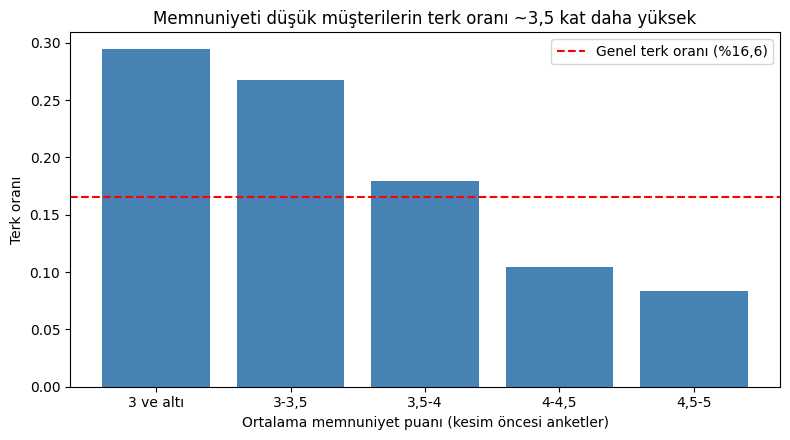

In [37]:
# Amaç: Ortanca farkı küçük (4,00 / 3,78). Gruplara bölünce ilişki ne kadar güçlü?
rfm['memnuniyet_grup'] = pd.cut(rfm['ort_memnuniyet'], bins=[0, 3, 3.5, 4, 4.5, 5],
                                labels=['3 ve altı', '3-3,5', '3,5-4', '4-4,5', '4,5-5'], include_lowest=True)
ozet = rfm.groupby('memnuniyet_grup', observed=True)['churn'].agg(terk_orani='mean', musteri_sayisi='size')
print(ozet.round(3))

# Hiç ankete cevap vermeyenler: "cevap vermemek ilgisizlik işareti" hipotezi
print('\nHiç cevap vermeyenler:', rfm.loc[rfm['ort_memnuniyet'].isna(), 'churn']
      .agg(['mean', 'size']).round(3).to_dict())

# Kontrol: Etki araç yaşından mı geliyor? (eski araçlar daha memnuniyetsiz olabilir)
mem_kaba = pd.cut(rfm['ort_memnuniyet'], bins=[0, 3.5, 4, 5], labels=['3,5 ve altı', '3,5-4', '4 üstü'], include_lowest=True)
print('\nYaşa göre ortalama memnuniyet:', rfm.groupby('yas_grubu', observed=True)['ort_memnuniyet'].mean().round(2).to_dict())
print('Aynı yaş grubunda terk oranı (sütun: memnuniyet):')
print(pd.crosstab(rfm['yas_grubu'], mem_kaba, values=rfm['churn'], aggfunc='mean').round(3))

# Grafik
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ozet.index.astype(str), ozet['terk_orani'], color='steelblue')
ax.axhline(rfm['churn'].mean(), color='red', linestyle='--', label='Genel terk oranı (%16,6)')
ax.set_ylabel('Terk oranı')
ax.set_xlabel('Ortalama memnuniyet puanı (kesim öncesi anketler)')
ax.set_title('Memnuniyeti düşük müşterilerin terk oranı ~3,5 kat daha yüksek')
ax.legend()
plt.tight_layout()
plt.savefig(CIKTI + 'bulgu3_memnuniyet.png', dpi=150, bbox_inches='tight')
plt.show()

In [38]:
# Sonuç:
# - Memnuniyet düştükçe terk düzenli olarak artıyor: 4,5–5 puanda %8, 3 ve altında %29 (~3,5 kat).
#   Ortanca farkı küçük (4,00 / 3,78) çünkü müşterilerin çoğu 3,5–4,5 arasında; uçlardaki fark ortalamada eriyor.
# - Hiç ankete cevap vermeyen 47 müşteride terk %13 (genelden düşük) → "cevap vermemek ilgisizlik işareti" desteklenmedi.
# - Eski araçlar daha memnuniyetsiz (4,15 → 3,73), ama her yaş grubunda düşük memnuniyet ~2 kat terk
#   → memnuniyetin etkisi yaştan bağımsız.
# - Bu bir ilişki, neden-sonuç değil: memnuniyetsizliğin terke yol açtığı bu veriyle kanıtlanamaz.

## 1.4 Servis merkezi memnuniyeti

Bu soru merkezlerin performansını ölçüyor, tahmin yapmıyor; bu yüzden bütün (temizlenmiş) servis kayıtları kullanılıyor.

In [39]:
# 1) Hızlı cevap: merkez ortalamaları. Anket cevap oranı da bakılıyor (ölçüm her merkezde aynı mı?)
merkez = servis.groupby('servis_merkezi').agg(
    islem_sayisi=('kayit_id', 'count'),
    ort_memnuniyet=('memnuniyet_puani', 'mean'),
    anket_cevap_orani=('memnuniyet_puani', lambda x: x.notna().mean()),
)
print(merkez.sort_values('ort_memnuniyet').round(3))

# 2) Merkezler aynı işi mi yapıyor? (iş türü dağılımı, satır bazında yüzde)
print()
print(pd.crosstab(servis['servis_merkezi'], servis['servis_tipi'], normalize='index').round(2))

# 3) İş türüne göre memnuniyet
print('\nİş türüne göre ortalama memnuniyet:', servis.groupby('servis_tipi')['memnuniyet_puani'].mean().round(2).to_dict())

# 4) Adil karşılaştırma: aynı iş türü içinde merkezler
print()
print(servis.pivot_table(index='servis_merkezi', columns='servis_tipi',
                         values='memnuniyet_puani', aggfunc='mean').round(2))

                islem_sayisi  ort_memnuniyet  anket_cevap_orani
servis_merkezi                                                 
SM-İzmir1               3708            3.91               0.79
SM-Maslak              10376            3.91               0.79
SM-Bursa1               3153            3.93               0.79
SM-Antalya1             2926            3.95               0.80
SM-Kocaeli1             2693            3.95               0.79
SM-Kadıköy              5381            3.96               0.79
SM-Ankara1              4223            3.99               0.79

servis_tipi     Arıza Onarım  Kaporta/Boya  Lastik/Balans  Periyodik Bakım
servis_merkezi                                                            
SM-Ankara1              0.14          0.05           0.12             0.69
SM-Antalya1             0.14          0.06           0.11             0.69
SM-Bursa1               0.14          0.05           0.11             0.70
SM-Kadıköy              0.15          0.06      

In [40]:
# Sonuç:
# 1) Hızlı cevap: ortalamalar 3,91–3,99 arası, fark 5 üzerinden 0,08. En altta İzmir1 ve Maslak
#    (ekranda ikisi de 3,91; daha fazla basamakla İzmir1 3,906, Maslak 3,911 → en altta İzmir1).
#    Anket cevap oranı her merkezde %79–80 → ölçüm adil.
# 2) Maslak farklı bir iş yapıyor: işlerinin %34'ü arıza onarım (diğerlerinde %14–16), periyodik bakım %48 (diğerlerinde ~%69).
# 3) Arıza onarım en düşük puanı alan iş (3,50), periyodik bakım en yüksek (4,07).
#    → Maslak'ın ortalaması, en düşük puan alan işten çok yaptığı için düşük.
# 4) Aynı iş türü içinde Maslak dört kategorinin dördünde de en yüksek puanı alıyor (Simpson paradoksu).

                gercek  beklenen   fark
servis_merkezi                         
SM-İzmir1        3.906     3.972 -0.066
SM-Bursa1        3.931     3.977 -0.046
SM-Antalya1      3.950     3.979 -0.029
SM-Kocaeli1      3.953     3.977 -0.024
SM-Kadıköy       3.962     3.976 -0.014
SM-Ankara1       3.993     3.977  0.015
SM-Maslak        3.911     3.857  0.054

                mean  alt  ust  count
servis_merkezi                       
SM-İzmir1       3.35 3.27 3.42    423
SM-Kocaeli1     3.38 3.27 3.49    280
SM-Antalya1     3.40 3.30 3.50    301
SM-Bursa1       3.48 3.39 3.56    335
SM-Kadıköy      3.51 3.44 3.57    568
SM-Ankara1      3.51 3.43 3.59    452
SM-Maslak       3.55 3.51 3.58   2629


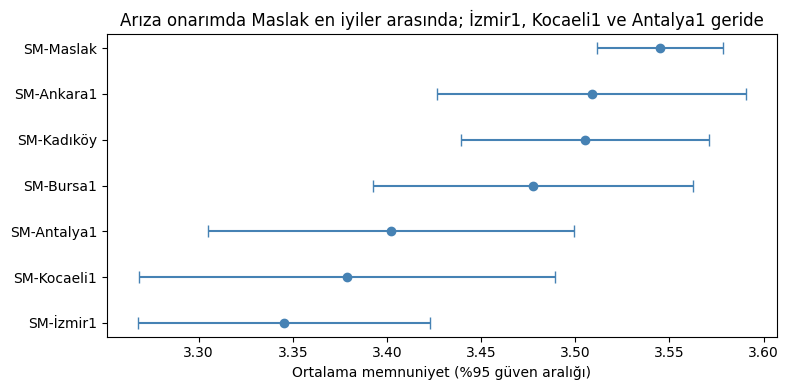

In [41]:
puanli = servis.dropna(subset=['memnuniyet_puani']).copy()

# 1) İş türü karışımına göre düzeltilmiş karşılaştırma
#    beklenen: her işlem için o iş türünün genel ortalaması → merkezin iş karışımından beklenen puan
puanli['beklenen'] = puanli['servis_tipi'].map(puanli.groupby('servis_tipi')['memnuniyet_puani'].mean())
duzeltilmis = puanli.groupby('servis_merkezi').agg(gercek=('memnuniyet_puani', 'mean'),
                                                    beklenen=('beklenen', 'mean'))
duzeltilmis['fark'] = duzeltilmis['gercek'] - duzeltilmis['beklenen']
print(duzeltilmis.sort_values('fark').to_string(float_format='{:.3f}'.format))

# 2) Farklar tesadüf mü? Arıza onarımda %95 güven aralığı (aralıklar örtüşmüyorsa fark büyük ihtimalle gerçek)
ariza = (puanli[puanli['servis_tipi'] == 'Arıza Onarım']
         .groupby('servis_merkezi')['memnuniyet_puani'].agg(['mean', 'std', 'count']))
ariza['hata'] = 1.96 * ariza['std'] / np.sqrt(ariza['count'])
ariza = ariza.sort_values('mean')
print()
print(ariza.assign(alt=ariza['mean'] - ariza['hata'], ust=ariza['mean'] + ariza['hata'])
      [['mean', 'alt', 'ust', 'count']].round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ariza['mean'], ariza.index, xerr=ariza['hata'], fmt='o', color='steelblue', capsize=4)
ax.set_xlabel('Ortalama memnuniyet (%95 güven aralığı)')
ax.set_title('Arıza onarımda Maslak en iyiler arasında; İzmir1, Kocaeli1 ve Antalya1 geride')
plt.tight_layout()
plt.savefig(CIKTI + 'merkez_ariza_guven_araligi.png', dpi=150, bbox_inches='tight')
plt.show()

In [42]:
# Sonuç:
# 1) İş türü karışımına göre düzeltilince sıralama tersine dönüyor:
#    Maslak beklenenin en çok üstünde olan merkez (+0,054), İzmir1 en çok altında olan (−0,066).
#    Maslak'tan beklenen puan zaten düşük (3,86), çünkü işlerinin üçte biri arıza onarım.
# 2) Arıza onarımda Maslak'ın aralığı (3,51–3,58) İzmir1, Kocaeli1 ve Antalya1'in aralıklarıyla örtüşmüyor
#    → fark büyük ihtimalle gerçek. Ankara1 ve Kadıköy ile örtüşüyor → Maslak "en iyiler arasında", tek başına en iyi değil.
#    Maslak'ın aralığı dar, çünkü 2.629 puanı var; diğerlerinin 280–570.
# 3) Bütün farklar küçük (5 üzerinden 0,1 civarı).

İş birimine söyleyeceğim cümle:

Merkezlerin memnuniyet puanları birbirine çok yakın. Maslak listenin altında görünüyor, çünkü müşterilerin en düşük puan verdiği arıza onarımı işlerinin büyük kısmı orada yapılıyor; aynı tür işler karşılaştırıldığında Maslak en iyi merkezler arasında, bu yüzden Maslak için aksiyon önermiyoruz. Merkezleri iş türüne göre değerlendirdiğimizde en geride kalan İzmir1; özellikle arıza onarım işlerinde İzmir1, Kocaeli1 ve Antalya1'in süreçlerine bakmakta fayda var.

## Bölüm 1 — Özet

### 1.1 Analiz tablosu
- Dört dosya önce müşteri seviyesine özetlenip `musteri_id` ile birleştirildi (servis ve geri bildirim araca N'e N bağlı; satır seviyesinde birleştirme şişirir).
- Popülasyon: kesimden önce en az bir servisi olan **3.974 müşteri**. Tablo 17 sütun → `ciktilar/analiz_tablosu.csv`.
- RFM yalnızca kesim öncesi kayıtlardan; recency kesim tarihine göre. Ortancalar: 102 gün, 6 ziyaret, ~67.700 TL. Aynı araçta aynı gün birden fazla kayıt olmadığı için her servis kaydı bir ziyaret.
- Hedef: 2025-07-01 – 2026-06-30 arasında servis yoksa churn = 1 → **658 terk (%16,6)**.
- Sızıntı: `crm_musteri_durumu` ve `son_iletisim_notu` terk sonrası yazılmış ("Kaybedildi" ve dört not türü %100 terk) → kullanılmadı. Kesimden sonra alınan 180 araç ve satın almadan önceki 74 yorum dışarıda bırakıldı.

### 1.2 Veri kalitesi
| Sorun | Bulgu | Karar ve gerekçe |
|---|---|---|
| Kopyalar | 35 müşteri, 310 servis satırı birebir kopya; birleştirme +277 satır üretiyor | Silindi: bütün sütunlar aynı, bilgi kaybı yok; bırakılsa ziyaret ve harcama şişer |
| Tarih biçimleri | 4 biçim; 7.894 kayıt (~%24) gün/ay karışıklığına açık | Açık kalıplarla çevrildi; ikinci sayı hiçbir kayıtta 12'yi geçmiyor → gün/ay/yıl doğrulandı |
| Tutar | 43 kayıt ≥100 bin, 150 negatif, 220 sıfır | Büyük → boş (normalin 33–278 katı, sabit çarpan yok); negatif → mutlak değer (iade eşleşmesi yok, aracın normalinin 1,03 katı); sıfır → boş (garantiyle açıklanmıyor). Std 37.232 → 7.852 |

Diğer: 40 negatif km mutlak değere çevrildi; şehir 21 yazım → 7 (Türkçe İ sorunu); memnuniyet boşlukları rastgele değil (arıza onarımda %26, periyodik bakımda %19) → ortalamayla doldurulmadı. Doğum yılında imkânsız değerler var, kullanılmadı. Referans bütünlüğü tam, gizli kopya yok.

### 1.3 Terk eden ve kalanları ayıran üç bulgu
1. **Recency:** 6 aya kadar terk %9–14, sonra hızla artıyor (10+ ay %80). 180+ gün müşterilerin %21'i ama terk edenlerin %48'i; diğer yarı son 6 ayda gelmiş → recency tek başına yetmez.
2. **Araç yaşı ve kullanım:** Terk 0–4 yaşta %11, 9+ yaşta %24. Garantinin görünen etkisi (%10 / %19) büyük ölçüde yaştan geliyor. Aynı yaşta km arttıkça terk düşüyor (9+ yaş: %41 → %17) → risk "eski ve az kullanılan araç"ta.
3. **Memnuniyet:** Ortanca farkı küçük (4,00 / 3,78) ama ≤3 puanda terk %29, 4,5+ puanda %8. Etki her yaş grubunda devam ediyor. İlişki, neden-sonuç değil.

Ayrıca: Terk edenlerin %22'si aracını satmış (önlenebilir bir kayıp değil).

### 1.4 İş birimine cevap
Merkezlerin memnuniyet puanları birbirine çok yakın (3,91–3,99). Maslak listenin altında görünüyor, çünkü müşterilerin en düşük puan verdiği arıza onarımı işlerinin büyük kısmı orada yapılıyor; aynı tür işler karşılaştırıldığında Maslak en iyi merkezler arasında, bu yüzden Maslak için aksiyon önermiyoruz. İş türüne göre değerlendirildiğinde en geride kalan İzmir1; özellikle arıza onarım işlerinde İzmir1, Kocaeli1 ve Antalya1'in süreçlerine bakmakta fayda var.